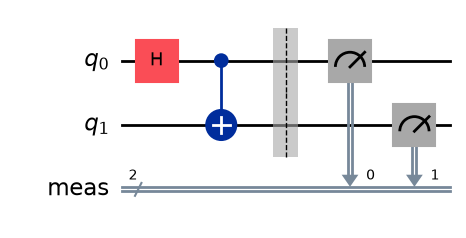

In [19]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)

qc.measure_all()

qc.draw("mpl")

The Hadamard gate followed by the CNOT gate creates an entangled Bell state. The theoretical probabilities of outcomes 00 and 11 are 50% each, while outcomes 01 and 10 have zero probability in an ideal circuit. Therefore, both qubits produce the same measurement result.

In [20]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

In [21]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

backend = service.least_busy()
print(backend.name)

ibm_fez


In [22]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

qc_isa = pm.run(qc)

In [23]:
sampler = Sampler(mode=backend)
pubs = [qc_isa]
jobs = sampler.run(pubs,shots=100)
res = jobs.result()
count  = res[0].data.meas.get_counts()

C:\Users\laksh\AppData\Local\Temp\ipykernel_20788\2837406280.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


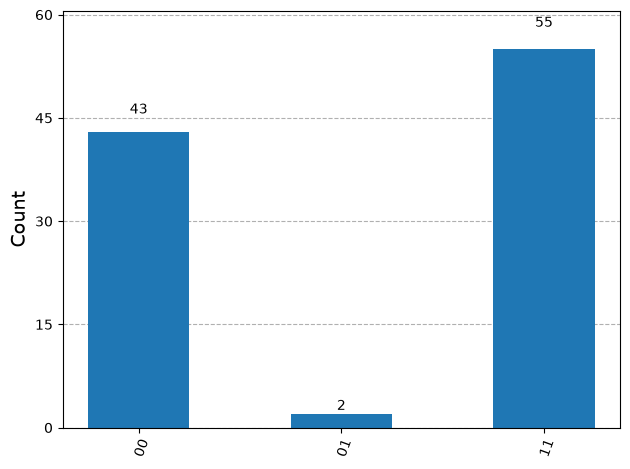

In [24]:
from qiskit.visualization import plot_histogram

plot_histogram(count)

As predicted the outcomes 00 and 11 are dominant in this circuit. Because they are the bell states and are entangled

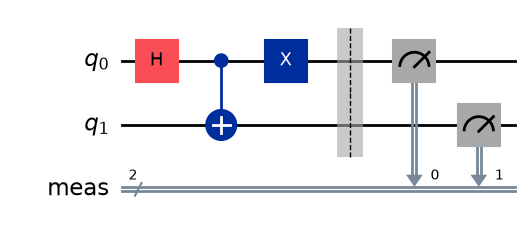

In [25]:
qc_modified = qc.copy()

qc_modified.remove_final_measurements(inplace=True)

qc_modified.x(0)

qc_modified.measure_all()

qc_modified.draw("mpl")


I copied the original circuit, removed its final measurements, and added an X gate to qubit 0 after the CNOT gate. The X gate flips qubit 0, changing the expected outcomes from 00 and 11 to 01 and 10. Each of these outcomes has a theoretical probability of 50%, so the qubits produce opposite measurement results.

In [26]:
qc_isa_m = pm.run(qc_modified)

In [27]:
sampler = Sampler(mode=backend)
pubs = [qc_isa_m]
jobs = sampler.run(pubs,shots=100)
res = jobs.result()
count  = res[0].data.meas.get_counts()

C:\Users\laksh\AppData\Local\Temp\ipykernel_20788\3124212929.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


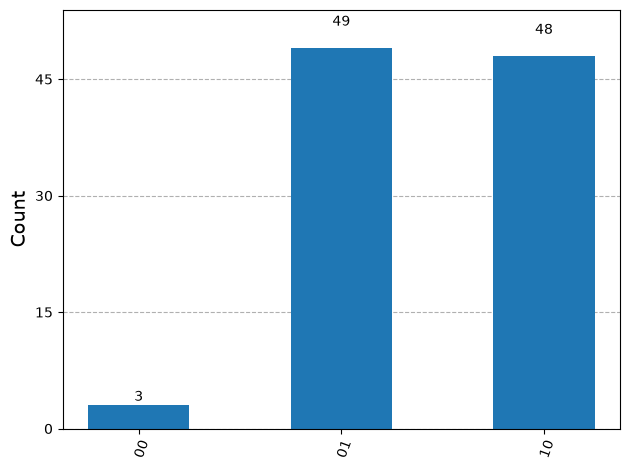

In [28]:
from qiskit.visualization import plot_histogram

plot_histogram(count)

Adding one X gate changes the measurement relationship from correlated to opposite while preserving the equal probabilities of the two allowed outcomes. Since the experiment uses real quantum hardware, the measured counts may differ from the theoretical predictions because of hardware noise and measurement errors.